In [4]:
# ============================================================
# IRIS DATASET CLASSIFICATION
# Logistic Regression vs Decision Tree
# ============================================================

# Step 1: Import Libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Step 2: Load Dataset

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(url)

print("First Five Rows:")
print(df.head())



First Five Rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [5]:
print("\nDataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

# Step 3: Exploratory Data Analysis

print("\nStatistical Summary:")
print(df.describe())

print("\nSpecies Distribution:")
print(df["species"].value_counts())



Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Statistical Summary:
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.057333      3.758000     1.199333
std        0.828066     0.435866      1.765298     0.762238
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000   

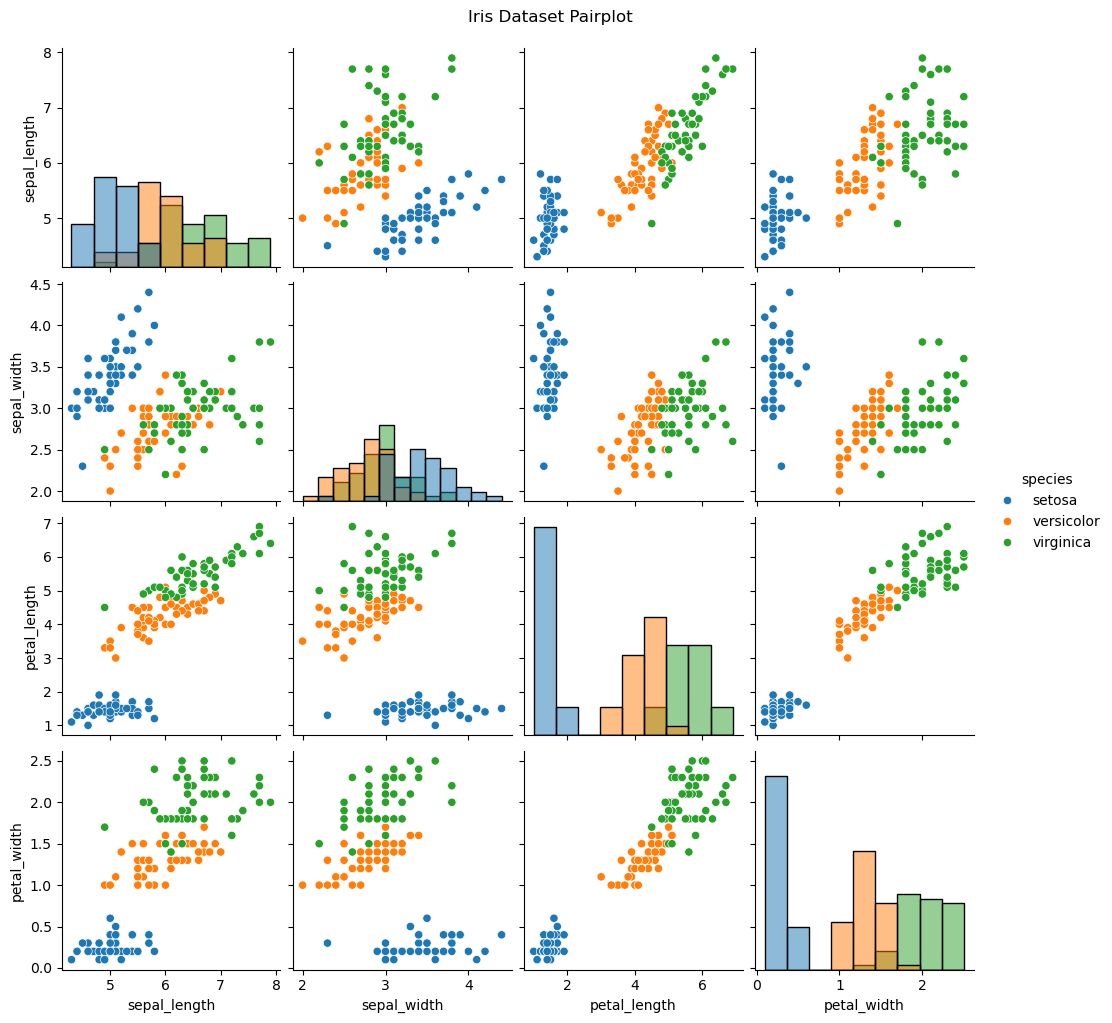


Features:
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2

Target:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


In [6]:
# Pairplot

sns.pairplot(df, hue="species", diag_kind="hist")
plt.suptitle("Iris Dataset Pairplot", y=1.02)
plt.show()

# Step 4: Separate Features and Target

X = df.drop("species", axis=1)
y = df["species"]

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())

In [7]:
# Step 5: Split Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))




Training Samples: 120
Testing Samples: 30


In [8]:
# Step 6: Create Classification Models

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(random_state=42))
    ])
}


In [9]:
# Step 7: Train Models and Evaluate Performance

results = {}
predictions = {}

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    results[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

    print("\n====================================")
    print(name)
    print("====================================")

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))


Logistic Regression
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1-Score: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1-Score: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30




Model Performance Comparison:
                     Accuracy  Precision  Recall  F1-Score
Logistic Regression    0.9333     0.9333  0.9333    0.9333
Decision Tree          0.9333     0.9333  0.9333    0.9333


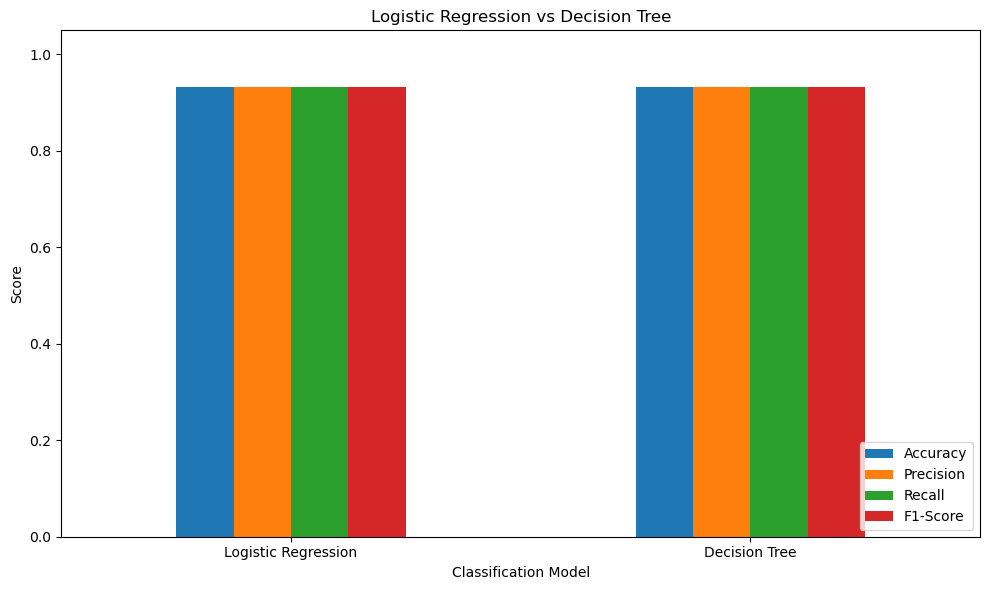

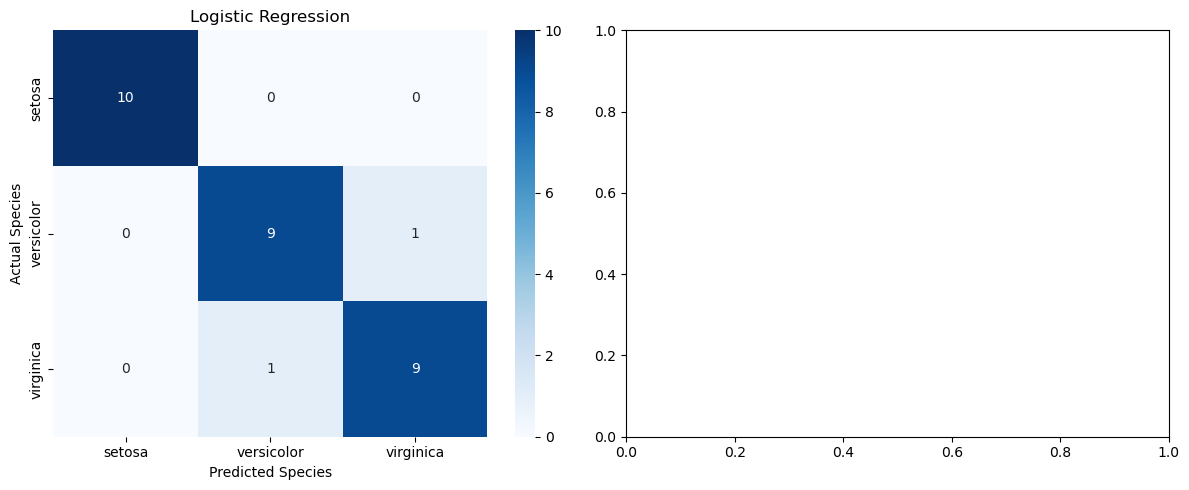

<Figure size 640x480 with 0 Axes>

In [10]:

# Step 8: Compare Model Performance

results_df = pd.DataFrame(results).T

print("\nModel Performance Comparison:")
print(results_df.round(4))

# Plot Performance Comparison

results_df.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.05)
)

plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Score")
plt.xlabel("Classification Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Step 9: Plot Confusion Matrix Heatmaps

class_labels = sorted(y.unique())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")
    plt.tight_layout()
    plt.show()



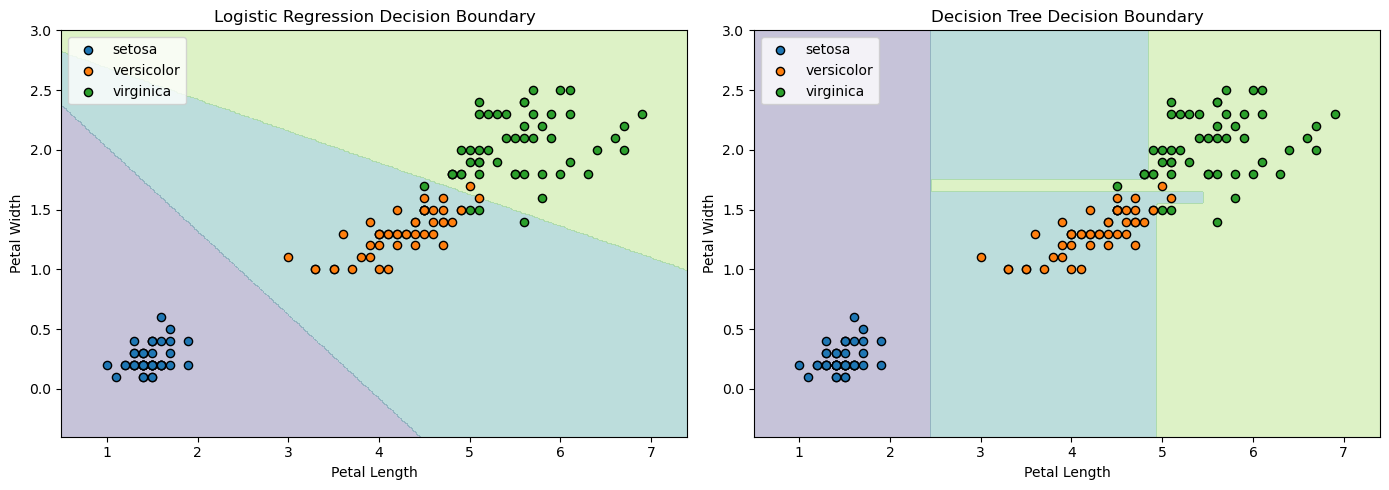


FINAL CONCLUSION
Best Model Based on Macro F1-Score: Logistic Regression

Final Performance:
                     Accuracy  Precision  Recall  F1-Score
Logistic Regression    0.9333     0.9333  0.9333    0.9333
Decision Tree          0.9333     0.9333  0.9333    0.9333


In [11]:
# Step 10: Decision Boundary Visualization
# Use two features for a 2D visualization.

features_2d = ["petal_length", "petal_width"]

X_2d = df[features_2d]
y_2d = df["species"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d,
    y_2d,
    test_size=0.20,
    random_state=42,
    stratify=y_2d
)

visual_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(random_state=42))
    ])
}

# Train visualization models

for model in visual_models.values():
    model.fit(X2_train, y2_train)

# Create mesh grid

x_min = X_2d["petal_length"].min() - 0.5
x_max = X_2d["petal_length"].max() + 0.5

y_min = X_2d["petal_width"].min() - 0.5
y_max = X_2d["petal_width"].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = pd.DataFrame({
    "petal_length": xx.ravel(),
    "petal_width": yy.ravel()
})

class_names = sorted(y_2d.unique())
class_to_int = {
    name: index for index, name in enumerate(class_names)
}

# Plot decision boundaries

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, model) in zip(
    axes, visual_models.items()
):

    predictions_grid = model.predict(grid)

    Z = np.array([
        class_to_int[label]
        for label in predictions_grid
    ]).reshape(xx.shape)

    ax.contourf(
        xx,
        yy,
        Z,
        alpha=0.3,
        levels=np.arange(len(class_names) + 1) - 0.5,
        cmap="viridis"
    )

    for species in class_names:

        subset = X_2d[y_2d == species]

        ax.scatter(
            subset["petal_length"],
            subset["petal_width"],
            label=species,
            edgecolors="black",
            s=35
        )

    ax.set_title(name + " Decision Boundary")
    ax.set_xlabel("Petal Length")
    ax.set_ylabel("Petal Width")
    ax.legend()

plt.tight_layout()
plt.show()

# Step 11: Final Conclusion

best_model = results_df["F1-Score"].idxmax()

print("\n====================================")
print("FINAL CONCLUSION")
print("====================================")

print("Best Model Based on Macro F1-Score:", best_model)

print("\nFinal Performance:")
print(results_df.round(4))
